# Customer Intelligence with AI, Machine Learning and NLP
## Meridian Financial Services | Responsible AI case study

**Project objective:** Build an explainable customer-intelligence workflow to explore complaint-escalation risk, analyse support-ticket sentiment and themes, audit subgroup performance, and present findings in Power BI.

**Methods:** Exploratory data analysis, Logistic Regression, Random Forest, Azure AI Language sentiment and key-phrase extraction, subgroup fairness assessment, SHAP explanations, and Power BI reporting.

**Important limitation:** This project uses simulated data. The classification models showed weak overall discrimination and are presented for human-reviewed analytical decision support only—not automated customer decisions.

### Notebook roadmap
1. Environment and dependencies
2. Load and validate customer/outcome data
3. Exploratory analysis
4. Escalation-risk modelling and threshold selection
5. NLP analysis of support tickets and customer reviews
6. Fairness and subgroup performance audit
7. SHAP model explainability
8. Export analytical outputs for Power BI

> **Reproducibility:** Keep the four `meridian_*.csv` source files in the project data directory. Configure Azure credentials through environment variables; never commit credentials to GitHub.


In [1]:
# Import project dependencies

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import scipy

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("\nCore packages are working!")

Pandas: 3.0.3
NumPy: 2.4.6
Scikit-learn: 1.9.0
SciPy: 1.18.0

Core packages are working!


## 1. Environment and dependencies
Install the libraries required for data preparation, modelling, explainability, NLP, and Azure AI Language. In a clean environment, consider installing these from a project-level `requirements.txt` file.

In [2]:
%pip install shap vaderSentiment spacy azure-ai-textanalytics

Note: you may need to restart the kernel to use updated packages.


In [3]:
import shap
import spacy
import azure.ai.textanalytics
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

print("SHAP: OK")
print("spaCy: OK")
print("VADER: OK")
print("Azure AI Text Analytics: OK")

SHAP: OK
spaCy: OK
VADER: OK
Azure AI Text Analytics: OK


In [ ]:
import os
from pathlib import Path

# Run the notebook from the project directory, or update DATA_DIR to your local data folder.
DATA_DIR = Path.cwd()
required_files = [
    "meridian_customers.csv",
    "meridian_outcomes.csv",
    "meridian_tickets.csv",
    "meridian_reviews.csv",
]
missing_files = [name for name in required_files if not (DATA_DIR / name).exists()]
if missing_files:
    raise FileNotFoundError(
        "Place the required CSV files in DATA_DIR or update DATA_DIR. Missing: "
        + ", ".join(missing_files)
    )
os.chdir(DATA_DIR)
print(f"Project data directory: {DATA_DIR.resolve()}")

## 2. Load and validate the structured data
Load customer profiles and outcome labels, then validate the join and inspect missing values and duplicate rows before analysis.

In [5]:
# Load source datasets 
import pandas as pd

customers = pd.read_csv("meridian_customers.csv")
outcomes = pd.read_csv("meridian_outcomes.csv")
tickets = pd.read_csv("meridian_tickets.csv")
reviews = pd.read_csv("meridian_reviews.csv")

print(customers.shape)
print(outcomes.shape)
print(tickets.shape)
print(reviews.shape)

(500, 8)
(500, 5)
(919, 7)
(310, 6)


In [6]:
# Merge customer and outcome records with one-to-one validation
df = customers.merge(
    outcomes,
    on="customer_id",
    how="inner",
    validate="one_to_one"
)

print("Shape after merge:", df.shape)
print(f'Escalation rate:   {df["escalated"].mean():.1%}') 
print(df.info()) 

Shape after merge: (500, 12)
Escalation rate:   26.8%
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   customer_id          500 non-null    str  
 1   age_band             500 non-null    str  
 2   product_type         500 non-null    str  
 3   region               500 non-null    str  
 4   primary_channel      500 non-null    str  
 5   tenure_months        500 non-null    int64
 6   account_value_gbp    500 non-null    int64
 7   previous_complaints  500 non-null    int64
 8   escalated            500 non-null    bool 
 9   churned              500 non-null    bool 
 10  complaint_count_12m  500 non-null    int64
 11  nps_score            500 non-null    int64
dtypes: bool(2), int64(5), str(5)
memory usage: 59.4 KB
None


In [7]:
# Validate missing values and duplicate records

print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

customer_id            0
age_band               0
product_type           0
region                 0
primary_channel        0
tenure_months          0
account_value_gbp      0
previous_complaints    0
escalated              0
churned                0
complaint_count_12m    0
nps_score              0
dtype: int64
Duplicate rows: 0


In [8]:
 
print(f'Shape after merge: {df.shape}') 


Shape after merge: (500, 12)


## 3. Exploratory data analysis
Compare complaint-escalation rates across product type, previous-complaint history, and age band. Use the results to frame the modelling task and identify fairness-sensitive dimensions.

In [9]:
# Escalation rate by product type 
prod_esc = df.groupby('product_type')['escalated'].mean().sort_values(ascending=False) 
print('Escalation rate by product:') 
print((prod_esc * 100).round(1))

Escalation rate by product:
product_type
Personal Loan      36.5
Home Insurance     31.0
Credit Card        29.6
Current Account    24.2
Savings Account    19.3
Mortgage           18.9
Name: escalated, dtype: float64


In [10]:

# Previous complaints vs escalation 
print('\nEscalation rate by previous_complaints:') 
print((df.groupby('previous_complaints')['escalated'].mean() * 100).round(1))


Escalation rate by previous_complaints:
previous_complaints
0    25.6
1    19.5
2    41.1
3    31.2
4    60.0
Name: escalated, dtype: float64


**Observation:** Escalation rates vary by the number of previous complaints. Customers with four previous complaints have the highest escalation rate at 60.0%, while those with one previous complaint have the lowest at 19.5%.

**Insight:** Previous complaint history appears to be associated with escalation risk and may provide useful predictive information for the classification model.

In [11]:

# Escalation rate by age band 
age_esc = df.groupby('age_band')['escalated'].mean() 
print('\nEscalation rate by age band:') 
print((age_esc * 100).round(1)) 


Escalation rate by age band:
age_band
18-25    24.2
26-35    30.1
36-45    30.1
46-55    25.0
56-65    21.9
65+      23.9
Name: escalated, dtype: float64


**Observation:** Escalation rates vary across age bands, ranging from 21.9% for customers aged 56–65 to 30.1% for customers aged 26–35 and 36–45.

**Insight:** Age band shows some variation in escalation rates and will be considered as a feature in the classification model, while also being monitored as a potential protected-characteristic proxy.

C:\Users\Acer\AppData\Local\Temp\ipykernel_20476\4215047020.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='escalated', y='previous_complaints',


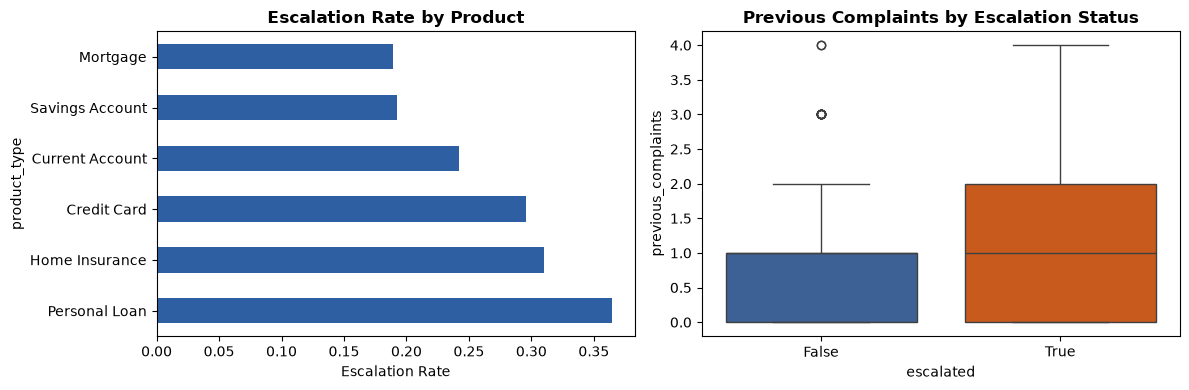

In [12]:

# Visualise: escalation rate by product 
fig, axes = plt.subplots(1, 2, figsize=(12, 4)) 
prod_esc.plot(kind='barh', ax=axes[0], color='#2E5FA3') 
axes[0].set_title('Escalation Rate by Product', fontweight='bold') 
axes[0].set_xlabel('Escalation Rate')


# Previous complaints boxplot 
sns.boxplot(data=df, x='escalated', y='previous_complaints', 
            ax=axes[1], palette=['#2E5FA3','#E65100']) 
axes[1].set_title('Previous Complaints by Escalation Status', fontweight='bold') 
plt.tight_layout() 
plt.savefig('eda_escalation.png', dpi=150) 
plt.show() 

**Observation:** Escalated customers generally have a higher number of previous complaints than non-escalated customers, although some non-escalated customers also have relatively high complaint histories.

**Insight:** Previous complaint history appears to provide a useful signal for escalation risk and should be included as a predictive feature in the classification model.

## 4. Escalation-risk classification
Prepare features, split the data using stratification, train Logistic Regression and Random Forest, and compare their performance. Interpret the probability threshold using the relative business costs of false negatives and false positives.

In [13]:
# Prepare features and define the classification task
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# Define features and target
feature_cols = [
    'tenure_months',
    'account_value_gbp',
    'previous_complaints',
    'age_band',
    'product_type',
    'primary_channel',
    'region'
]

target_col = 'escalated'

# Encode categorical variables
df_model = pd.get_dummies(
    df[feature_cols + [target_col]],
    columns=['age_band', 'product_type', 'primary_channel', 'region'],
    drop_first=True
)

X = df_model.drop(target_col, axis=1)
y = df_model[target_col].astype(int)

print(f'Features: {X.shape[1]}')
print(f'Target balance: {y.mean():.1%} escalated')

Features: 22
Target balance: 26.8% escalated


In [14]:
# Split with stratification to preserve class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (400, 22)
Test set: (100, 22)


In [15]:
# Logistic Regression
lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)

rf_model.fit(X_train_scaled, y_train)

print("Both models trained successfully.")

Both models trained successfully.


In [16]:
# Evaluate both models
for name, model in [
    ('Logistic Regression', lr_model),
    ('Random Forest', rf_model)
]:
    preds = model.predict(X_test_scaled)
    proba = model.predict_proba(X_test_scaled)[:, 1]

    print(f'\n=== {name} ===')
    print(classification_report(
        y_test,
        preds,
        target_names=['Not Escalated', 'Escalated']
    ))
    print(f'AUC: {roc_auc_score(y_test, proba):.3f}')


=== Logistic Regression ===
               precision    recall  f1-score   support

Not Escalated       0.73      0.48      0.58        73
    Escalated       0.27      0.52      0.35        27

     accuracy                           0.49       100
    macro avg       0.50      0.50      0.47       100
 weighted avg       0.60      0.49      0.52       100

AUC: 0.486

=== Random Forest ===
               precision    recall  f1-score   support

Not Escalated       0.73      0.77      0.75        73
    Escalated       0.26      0.22      0.24        27

     accuracy                           0.62       100
    macro avg       0.49      0.49      0.49       100
 weighted avg       0.60      0.62      0.61       100

AUC: 0.525


In [17]:
# Use your chosen model's probability scores 
chosen_model = rf_model  # Change to lr_model if you chose Logistic Regression 
y_proba      = chosen_model.predict_proba(X_test_scaled)[:, 1] 
 
# Test three thresholds 
COST_FN = 800   # Cost of missing a high-risk customer (FOS case) 
COST_FP = 25    # Cost of unnecessary intervention 
 
print(f'{'Threshold':<12} {'TP':<6} {'FP':<6} {'FN':<6} {'TN':<6}' 
      f' {'Recall':<8} {'Precision':<12} {'Est Cost GBP'}') 
print('-' * 80) 
 
for thresh in [0.30, 0.40, 0.50]: 
    y_pred    = (y_proba >= thresh).astype(int) 
    tn,fp,fn,tp = confusion_matrix(y_test, y_pred).ravel() 
    precision = tp / (tp+fp) if (tp+fp)>0 else 0 
    recall    = tp / (tp+fn) if (tp+fn)>0 else 0 
    # Scale to full portfolio (test = 20%) 
    total_cost = (fn * COST_FN + fp * COST_FP) * 5 
    print(f'{thresh:<12} {tp:<6} {fp:<6} {fn:<6} {tn:<6}' 
          f' {recall:<8.3f} {precision:<12.3f} GBP {total_cost:,.0f}') 

Threshold    TP     FP     FN     TN     Recall   Precision    Est Cost GBP
--------------------------------------------------------------------------------
0.3          21     55     6      18     0.778    0.276        GBP 30,875
0.4          16     37     11     36     0.593    0.302        GBP 48,625
0.5          7      19     20     54     0.259    0.269        GBP 82,375


**Threshold recommendation:** A threshold of 0.30 is selected because it produces the lowest estimated business cost (£30,875) among the three tested thresholds. It also achieves the highest recall (77.8%), meaning the model identifies a larger proportion of customers who actually escalate. This is particularly important because a false negative has an estimated cost of £800, compared with £25 for a false positive.

**Business consideration:** The 0.30 threshold produces more false positives (55), so it would result in more customers receiving intervention. This should be managed through proportionate human review rather than automatic action.

## 5. NLP: Azure AI Language
Use Azure AI Language to analyse support-ticket sentiment and extract key phrases. Azure credentials are read from environment variables and must not be hard-coded into the notebook.

In [ ]:
import os
from azure.ai.textanalytics import TextAnalyticsClient
from azure.core.credentials import AzureKeyCredential

# Set these environment variables in your local environment; do not commit secrets.
ENDPOINT = os.environ.get("AZURE_LANGUAGE_ENDPOINT")
KEY = os.environ.get("AZURE_LANGUAGE_KEY")

if not ENDPOINT or not KEY:
    raise EnvironmentError(
        "Set AZURE_LANGUAGE_ENDPOINT and AZURE_LANGUAGE_KEY before running Azure NLP cells."
    )

client = TextAnalyticsClient(
    endpoint=ENDPOINT,
    credential=AzureKeyCredential(KEY)
)

test = client.analyze_sentiment(documents=["Test sentence."])
print("Azure AI Language connection successful:", test[0].sentiment)

In [19]:
tickets = pd.read_csv("meridian_tickets.csv")

sample = tickets.head(100)

print("Tickets loaded:", tickets.shape)
print("Sample size:", sample.shape)

Tickets loaded: (919, 7)
Sample size: (100, 7)


In [20]:
docs = list(sample['ticket_text'])

sentiments = []

for i in range(0, len(docs), 10):
    batch = docs[i:i+10]

    results = client.analyze_sentiment(documents=batch)

    for doc in results:
        if not doc.is_error:
            sentiments.append({
                'sentiment': doc.sentiment,
                'positive_score': doc.confidence_scores.positive,
                'neutral_score': doc.confidence_scores.neutral,
                'negative_score': doc.confidence_scores.negative
            })

sentiment_df = pd.DataFrame(sentiments)

print(sentiment_df['sentiment'].value_counts())

sentiment
negative    63
neutral     36
positive     1
Name: count, dtype: int64


In [21]:
all_phrases = []

for i in range(0, len(docs), 10):
    batch = docs[i:i+10]

    kp_results = client.extract_key_phrases(documents=batch)

    for doc in kp_results:
        if not doc.is_error:
            all_phrases.extend(doc.key_phrases)

from collections import Counter

phrase_counts = Counter(all_phrases)

top_phrases = pd.DataFrame(
    phrase_counts.most_common(20),
    columns=['phrase', 'count']
)

print(top_phrases)

                         phrase  count
0                       account     23
1         home insurance policy      9
2                        excess      9
3               billing dispute      7
4                   monthly fee      6
5                  notification      6
6        early repayment charge      5
7                          loan      5
8            unexplained charge      5
9                  last Tuesday      5
10             worst experience      5
11            financial company      5
12  multiple small transactions      4
13                 credit limit      4
14                      process      4
15                        terms      4
16                     mortgage      4
17                 direct debit      4
18                   wrong date      4
19               online banking      3


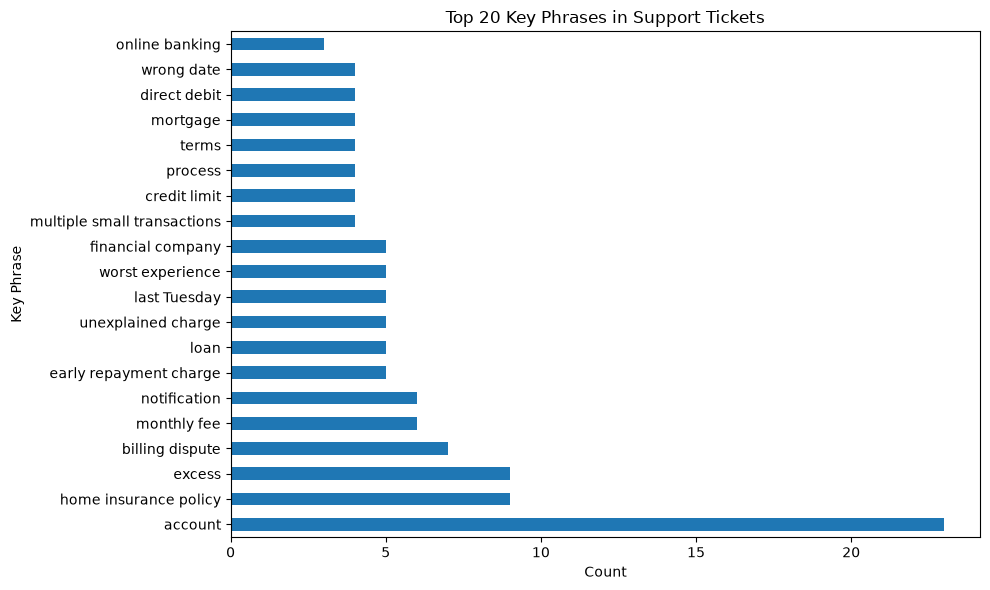

In [22]:
top_phrases.set_index('phrase')['count'].plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Top 20 Key Phrases in Support Tickets')
plt.xlabel('Count')
plt.ylabel('Key Phrase')
plt.tight_layout()

plt.savefig('key_phrases.png', dpi=150)
plt.show()

In [23]:
all_docs = list(tickets['ticket_text'])

all_sentiments = []

for i in range(0, len(all_docs), 10):
    batch = all_docs[i:i+10]

    results = client.analyze_sentiment(documents=batch)

    for doc in results:
        if not doc.is_error:
            all_sentiments.append(doc.sentiment)

sentiment_all_df = pd.DataFrame({
    'sentiment': all_sentiments
})

print("Documents analysed:", len(sentiment_all_df))
print("\nSentiment distribution:")
print(sentiment_all_df['sentiment'].value_counts())

Documents analysed: 919

Sentiment distribution:
sentiment
negative    628
neutral     269
positive     17
mixed         5
Name: count, dtype: int64


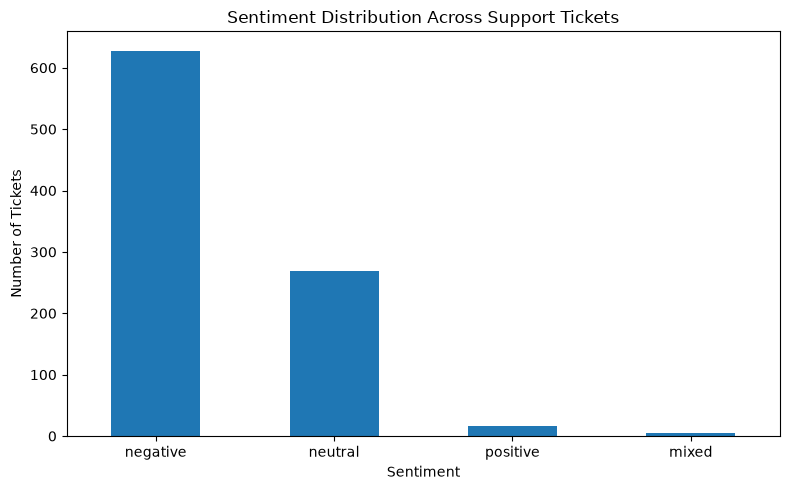

In [24]:
sentiment_counts = sentiment_all_df['sentiment'].value_counts()

sentiment_counts.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Sentiment Distribution Across Support Tickets')
plt.xlabel('Sentiment')
plt.ylabel('Number of Tickets')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig('sentiment_distribution.png', dpi=150)
plt.show()

**Insight:** The sentiment distribution indicates a predominantly negative customer experience. Approximately 68.3% of support tickets were classified as negative, compared with 29.3% neutral and only 1.8% positive. This suggests that negative customer interactions are widespread and should be investigated to identify the underlying service issues driving dissatisfaction.

In [25]:
print(tickets.columns.tolist())

['ticket_id', 'customer_id', 'ticket_date', 'category', 'resolution_time_hrs', 'resolved', 'ticket_text']


In [26]:
category_sentiments = []

for i in range(0, len(tickets), 10):
    batch = list(tickets['ticket_text'].iloc[i:i+10])

    results = client.analyze_sentiment(documents=batch)

    for doc in results:
        if not doc.is_error:
            category_sentiments.append({
                'sentiment': doc.sentiment,
                'positive_score': doc.confidence_scores.positive,
                'neutral_score': doc.confidence_scores.neutral,
                'negative_score': doc.confidence_scores.negative
            })

category_sentiment_df = pd.DataFrame(category_sentiments)

category_sentiment_df['category'] = tickets['category'].values

print(
    category_sentiment_df.groupby('category')[
        ['positive_score', 'neutral_score', 'negative_score']
    ].mean()
)

                 positive_score  neutral_score  negative_score
category                                                      
Account Access         0.000000       0.212242        0.786182
Billing                0.004500       0.087056        0.906167
Complaint              0.060484       0.080565        0.857419
Fraud Query            0.001826       0.381478        0.614522
Product Query          0.063717       0.745026        0.189581
Refund Request         0.000000       0.095625        0.904375
Service Failure        0.000000       0.011667        0.988021


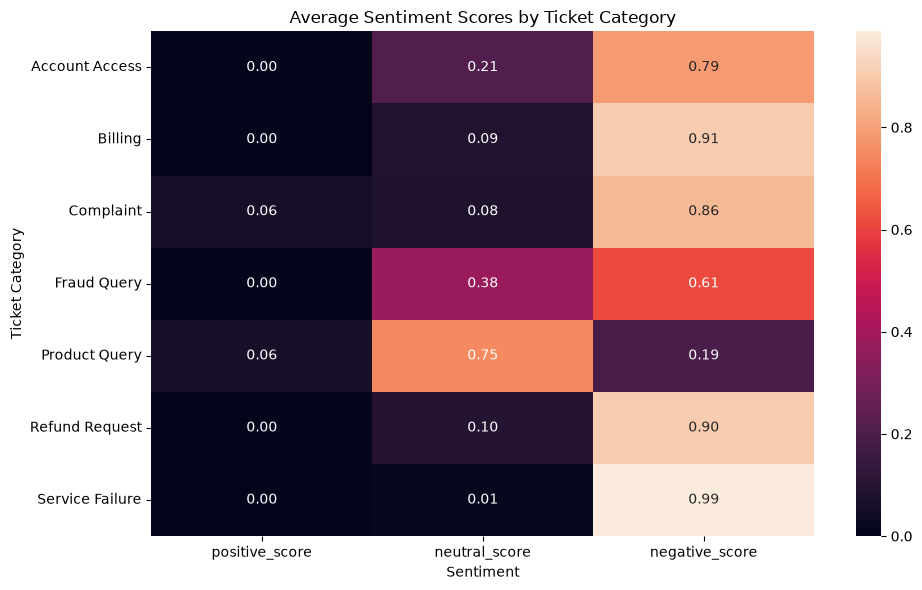

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

category_scores = category_sentiment_df.groupby('category')[
    ['positive_score', 'neutral_score', 'negative_score']
].mean()

plt.figure(figsize=(10, 6))

sns.heatmap(
    category_scores,
    annot=True,
    fmt='.2f'
)

plt.title('Average Sentiment Scores by Ticket Category')
plt.xlabel('Sentiment')
plt.ylabel('Ticket Category')
plt.tight_layout()

plt.savefig('sentiment_by_category.png', dpi=150)
plt.show()

In [28]:
print(tickets['category'].value_counts())

category
Product Query      191
Billing            180
Account Access     165
Complaint          124
Fraud Query        115
Service Failure     96
Refund Request      48
Name: count, dtype: int64


**Insight:** Service Failure generates the most negative sentiment, with an average negative confidence score of 0.99, followed by Billing (0.91) and Refund Request (0.90). However, Service Failure is not the highest-volume category. Product Query has the highest volume with 191 tickets but has the lowest negative sentiment score (0.19). This indicates that the most frequent customer issue is not necessarily the most negative, suggesting that management should prioritise both issue volume and severity when assessing customer experience.

In [29]:
sentiment_ticket_df = category_sentiment_df.copy()

sentiment_ticket_df['ticket_id'] = tickets['ticket_id'].values
sentiment_ticket_df['escalated'] = tickets['customer_id'].map(
    df.set_index('customer_id')['escalated']
).values

print(
    sentiment_ticket_df.groupby('escalated')['negative_score'].mean()
)

escalated
False    0.690074
True     0.731012
Name: negative_score, dtype: float64


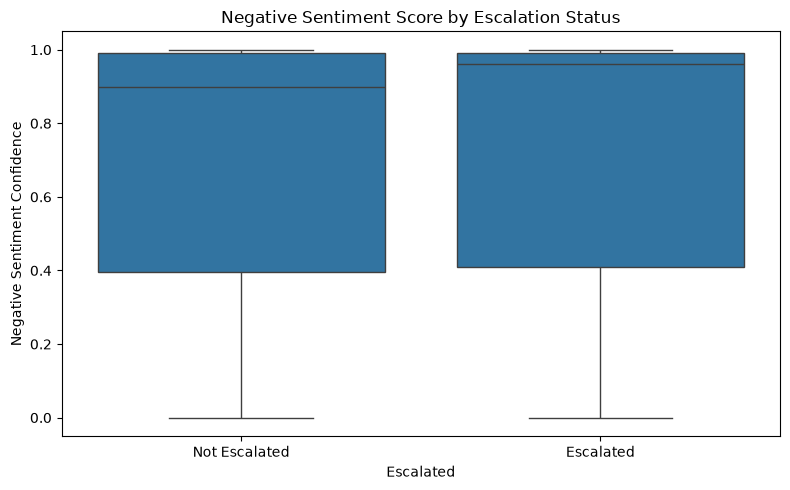

In [30]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=sentiment_ticket_df,
    x='escalated',
    y='negative_score'
)

plt.title('Negative Sentiment Score by Escalation Status')
plt.xlabel('Escalated')
plt.ylabel('Negative Sentiment Confidence')
plt.xticks([0, 1], ['Not Escalated', 'Escalated'])

plt.tight_layout()

plt.savefig('sentiment_vs_escalation.png', dpi=150)
plt.show()

**Insight:** Escalated tickets have a higher average negative sentiment confidence score (0.731) than non-escalated tickets (0.690), a difference of 0.041. This indicates that more negative customer sentiment is associated with escalation, although the relatively modest difference suggests that sentiment alone is unlikely to be sufficient for predicting escalation.

In [31]:
print(reviews.columns.tolist())

['review_id', 'customer_id', 'review_date', 'star_rating', 'product_type', 'review_text']


In [32]:
reviews['review_date'] = pd.to_datetime(reviews['review_date'])

monthly_rating = (
    reviews
    .groupby(reviews['review_date'].dt.to_period('M'))['star_rating']
    .mean()
    .reset_index()
)

monthly_rating['review_date'] = monthly_rating['review_date'].dt.to_timestamp()

print(monthly_rating)

C:\Users\Acer\AppData\Local\Temp\ipykernel_20476\2285985778.py:1: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  reviews['review_date'] = pd.to_datetime(reviews['review_date'])


   review_date  star_rating
0   2025-05-01     3.666667
1   2025-06-01     3.870968
2   2025-07-01     3.583333
3   2025-08-01     3.476190
4   2025-09-01     3.782609
5   2025-10-01     3.480000
6   2025-11-01     3.281250
7   2025-12-01     3.103448
8   2026-01-01     4.086957
9   2026-02-01     3.680000
10  2026-03-01     3.307692
11  2026-04-01     3.826087
12  2026-05-01     3.520000


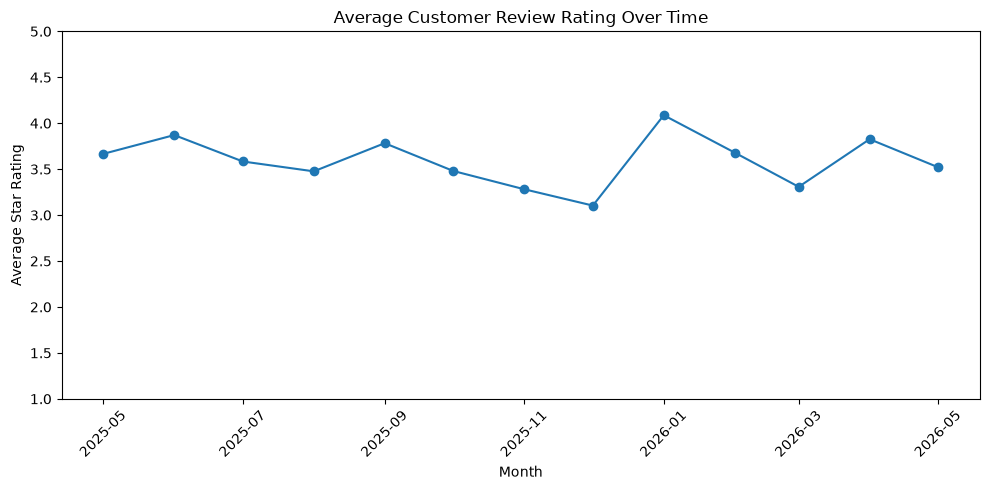

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_rating['review_date'],
    monthly_rating['star_rating'],
    marker='o'
)

plt.title('Average Customer Review Rating Over Time')
plt.xlabel('Month')
plt.ylabel('Average Star Rating')
plt.ylim(1, 5)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('review_sentiment_over_time.png', dpi=150)
plt.show()

**Insight:** Customer review ratings fluctuate over time rather than showing a consistent improvement or decline. The average rating fell from 3.87 in June 2025 to a low of 3.10 in December 2025, before rising sharply to 4.09 in January 2026. By May 2026, the average rating had fallen again to 3.52. This suggests that customer experience has been variable rather than following a sustained positive or negative trend.

## 6. Responsible AI: fairness and subgroup assessment
Evaluate recall and false-positive rates across age bands and product types. Interpret subgroup results cautiously because the test sample is small, and use material disparities as a reason to restrict deployment.

In [34]:
#  Responsible AI - Bias Audit and Fairness Assessment

test_idx = X_test.index

df_test = df.loc[test_idx].copy()

df_test['y_proba'] = chosen_model.predict_proba(X_test_scaled)[:, 1]

# Use the selected business threshold of 0.30
df_test['y_pred'] = (df_test['y_proba'] >= 0.30).astype(int)

df_test['y_true'] = y_test.values

print(df_test[['age_band', 'product_type', 'y_true', 'y_pred', 'y_proba']].head())

    age_band    product_type  y_true  y_pred  y_proba
206    56-65     Credit Card       0       1     0.50
132    26-35     Credit Card       0       1     0.53
425    26-35        Mortgage       0       1     0.40
455    46-55        Mortgage       0       1     0.48
69     56-65  Home Insurance       0       1     0.44


In [35]:
# model accuracy by age band
print("=== Model Performance by Age Band ===")

for band in sorted(df_test['age_band'].unique()):
    subset = df_test[df_test['age_band'] == band]

    accuracy = (subset['y_true'] == subset['y_pred']).mean()

    positives = subset[subset['y_true'] == 1]
    recall = (
        (positives['y_pred'] == 1).mean()
        if len(positives) > 0 else 0
    )

    print(
        f"{band:<10} "
        f"n={len(subset):<3} "
        f"accuracy={accuracy:.3f} "
        f"recall={recall:.3f}"
    )

=== Model Performance by Age Band ===
18-25      n=14  accuracy=0.357 recall=0.750
26-35      n=21  accuracy=0.381 recall=0.800
36-45      n=22  accuracy=0.545 recall=0.778
46-55      n=23  accuracy=0.217 recall=0.800
56-65      n=12  accuracy=0.250 recall=0.000
65+        n=8   accuracy=0.750 recall=1.000


In [36]:
# Evaluate model performance by product type
print("=== Model Performance by Product Type ===")

for product in sorted(df_test['product_type'].unique()):
    subset = df_test[df_test['product_type'] == product]

    accuracy = (subset['y_true'] == subset['y_pred']).mean()

    positives = subset[subset['y_true'] == 1]
    recall = (
        (positives['y_pred'] == 1).mean()
        if len(positives) > 0 else 0
    )

    print(
        f"{product:<20} "
        f"n={len(subset):<3} "
        f"accuracy={accuracy:.3f} "
        f"recall={recall:.3f}"
    )

=== Model Performance by Product Type ===
Credit Card          n=15  accuracy=0.333 recall=0.600
Current Account      n=30  accuracy=0.333 recall=0.571
Home Insurance       n=12  accuracy=0.333 recall=0.750
Mortgage             n=8   accuracy=0.250 recall=0.000
Personal Loan        n=16  accuracy=0.312 recall=1.000
Savings Account      n=19  accuracy=0.684 recall=1.000


In [37]:

# False Positive Rate = FP / (FP + TN) for each group 
# = fraction of non-escalating customers incorrectly flagged 
print('=== False Positive Rate by Age Band ===') 
for band in sorted(df_test['age_band'].unique()): 
    subset     = df_test[df_test['age_band'] == band] 
    negatives  = subset[subset['y_true'] == 0] 
    if len(negatives) == 0: continue 
    fpr        = (negatives['y_pred'] == 1).mean() 
    actual_esc = (subset['y_true'] == 1).mean() 
    print(f'  {band:<10}  FPR={fpr:.3f}  actual_esc_rate={actual_esc:.3f}') 

=== False Positive Rate by Age Band ===
  18-25       FPR=0.800  actual_esc_rate=0.286
  26-35       FPR=0.750  actual_esc_rate=0.238
  36-45       FPR=0.615  actual_esc_rate=0.409
  46-55       FPR=0.944  actual_esc_rate=0.217
  56-65       FPR=0.727  actual_esc_rate=0.083
  65+         FPR=0.400  actual_esc_rate=0.375


### Deployment Judgement

The fairness audit shows substantial variation in model performance across both age bands and product types. Recall varies considerably by age band, with particularly poor performance for customers aged 56–65, while product-level results show 0% recall for Mortgage customers.

The false positive rate also varies substantially across age bands, ranging from 40.0% for customers aged 65+ to 94.4% for customers aged 46–55. The high FPR for some groups means that many customers who would not actually escalate could be incorrectly flagged for intervention.

Given these disparities, the model should **not be deployed for automated customer decisions in its current form**. It should only be used as a decision-support tool with human review. The small subgroup sizes also mean that these results should be treated as indicative rather than conclusive, and further validation with a larger dataset would be required before deployment.

## 7. SHAP explainability
Use global feature importance and individual explanations to inspect how feature contributions affect selected predictions, including true-positive, false-positive, and false-negative examples.

In [38]:
import shap

# Create SHAP explainer for the Random Forest
explainer = shap.TreeExplainer(chosen_model)

# Calculate SHAP values for the test set
shap_values = explainer.shap_values(X_test_scaled)

# For binary classification, use class 1 = escalated
sv = shap_values[1] if isinstance(shap_values, list) else shap_values

print("SHAP values shape:", sv.shape)

SHAP values shape: (100, 22, 2)


In [39]:
sv = shap_values[:, :, 1]

print("Escalation SHAP values shape:", sv.shape)

Escalation SHAP values shape: (100, 22)


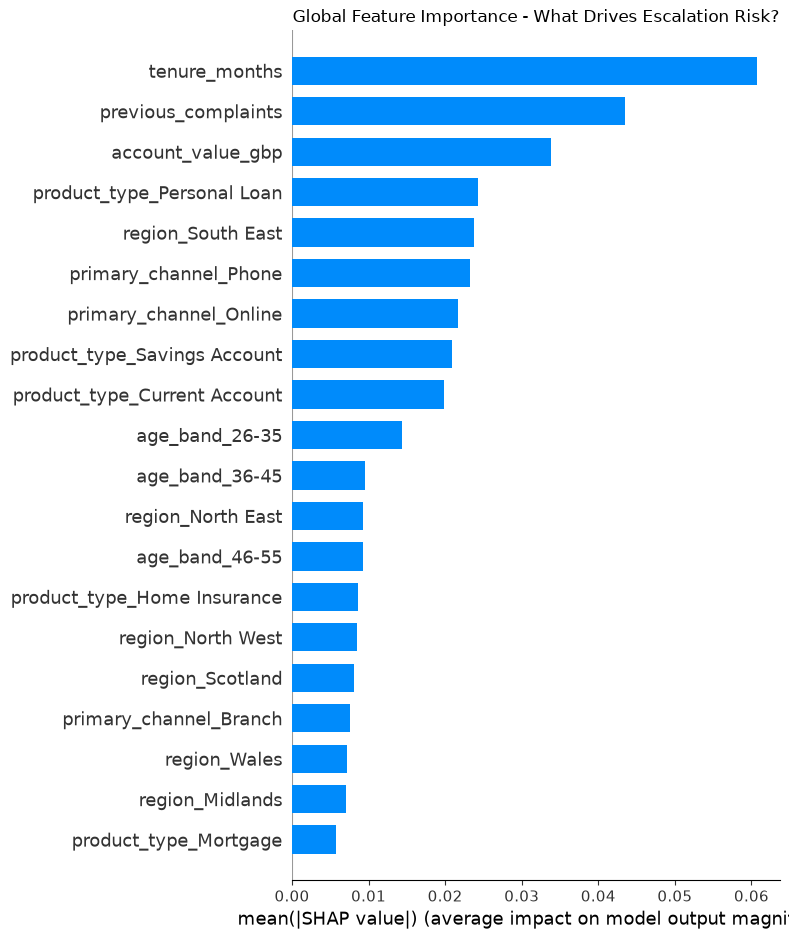

In [40]:
plt.figure(figsize=(10, 6))

shap.summary_plot(
    sv,
    X_test_scaled,
    feature_names=X.columns.tolist(),
    plot_type='bar',
    show=False
)

plt.title('Global Feature Importance - What Drives Escalation Risk?')
plt.tight_layout()
plt.savefig('shap_global.png', dpi=150)
plt.show()

In [41]:
# Reset the test-set index so it matches the SHAP values
df_test_idx = df_test.copy().reset_index(drop=True)

# Find one example of each prediction type
tp_idx = df_test_idx[
    (df_test_idx['y_true'] == 1) &
    (df_test_idx['y_pred'] == 1)
].index[0]

fp_idx = df_test_idx[
    (df_test_idx['y_true'] == 0) &
    (df_test_idx['y_pred'] == 1)
].index[0]

fn_idx = df_test_idx[
    (df_test_idx['y_true'] == 1) &
    (df_test_idx['y_pred'] == 0)
].index[0]

print("True Positive index:", tp_idx)
print("False Positive index:", fp_idx)
print("False Negative index:", fn_idx)

True Positive index: 9
False Positive index: 0
False Negative index: 14


In [42]:
print("TRUE POSITIVE")
print(df_test_idx.loc[tp_idx, ['customer_id', 'y_true', 'y_pred', 'y_proba']])

print("\nFALSE POSITIVE")
print(df_test_idx.loc[fp_idx, ['customer_id', 'y_true', 'y_pred', 'y_proba']])

print("\nFALSE NEGATIVE")
print(df_test_idx.loc[fn_idx, ['customer_id', 'y_true', 'y_pred', 'y_proba']])

TRUE POSITIVE
customer_id    CUS-0350
y_true                1
y_pred                1
y_proba            0.57
Name: 9, dtype: object

FALSE POSITIVE
customer_id    CUS-0207
y_true                0
y_pred                1
y_proba             0.5
Name: 0, dtype: object

FALSE NEGATIVE
customer_id    CUS-0136
y_true                1
y_pred                0
y_proba            0.18
Name: 14, dtype: object


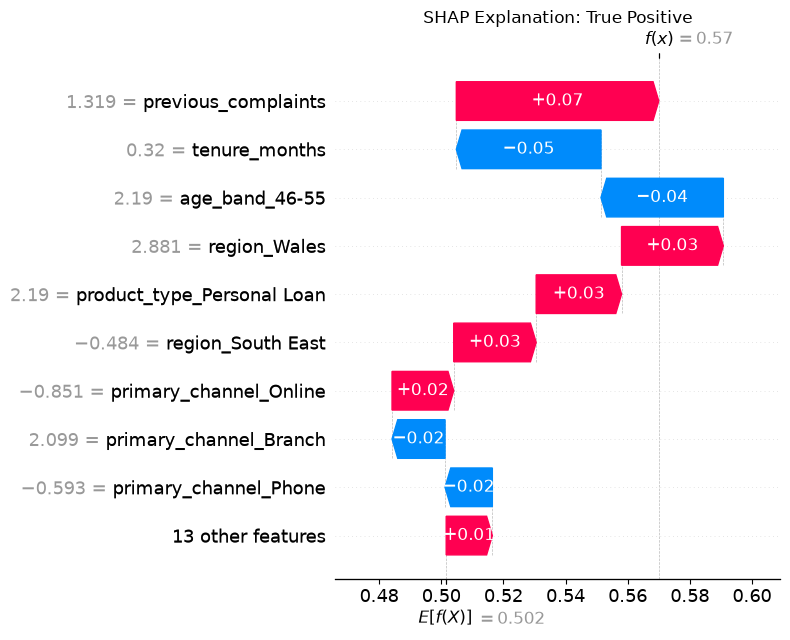

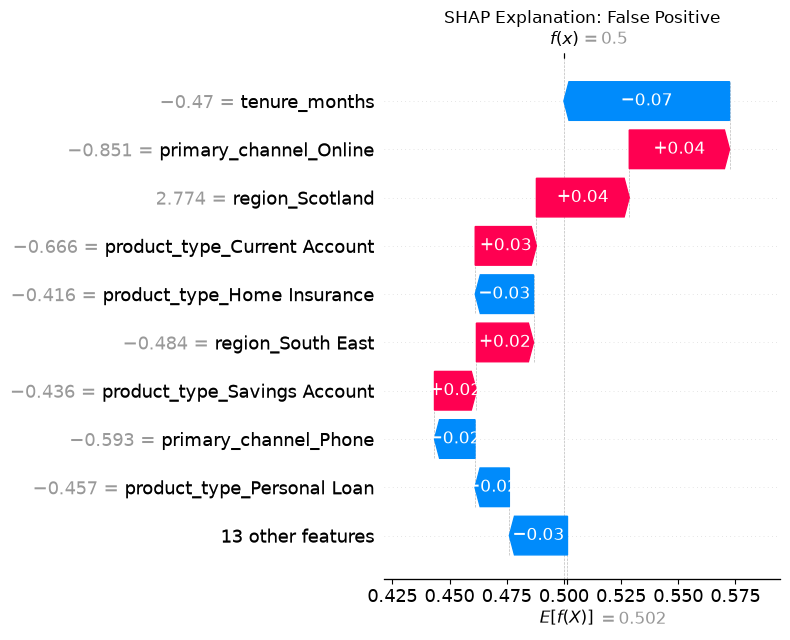

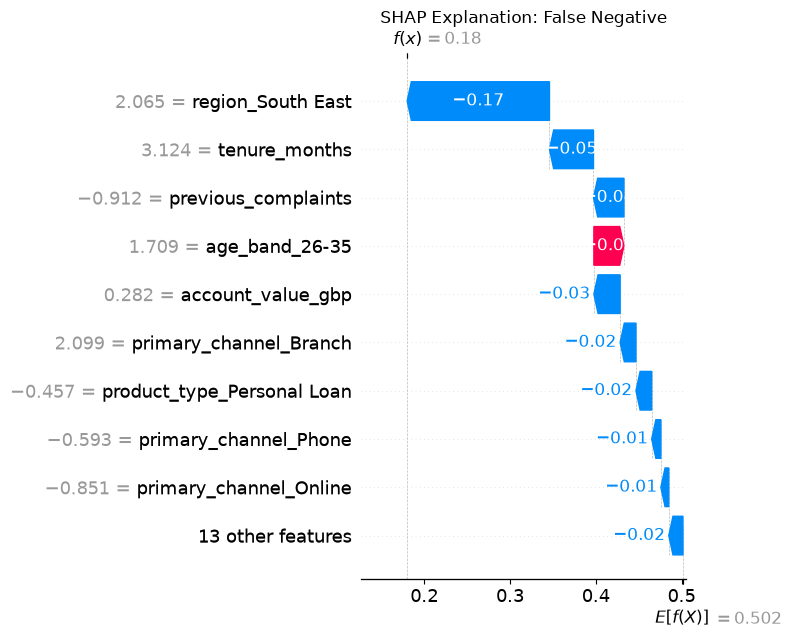

In [43]:
# Waterfall chart
for label, idx in [
    ('True Positive', tp_idx),
    ('False Positive', fp_idx),
    ('False Negative', fn_idx)
]:
    
    plt.figure(figsize=(10, 5))
    
    shap.waterfall_plot(
        shap.Explanation(
            values=sv[idx],
            base_values=explainer.expected_value[1],
            data=X_test_scaled[idx],
            feature_names=X.columns.tolist()
        ),
        show=False
    )
    
    plt.title(f'SHAP Explanation: {label}')
    plt.tight_layout()
    
    plt.savefig(
        f"shap_{label.lower().replace(' ', '_')}.png",
        dpi=150
    )
    
    plt.show()

In [44]:
# Select representative true-positive, false-positive, and false-negative cases
for label, idx in [
    ('True Positive', tp_idx),
    ('False Positive', fp_idx),
    ('False Negative', fn_idx)
]:
    print(f"\n=== {label} ===")
    
    customer_id = df_test_idx.loc[idx, 'customer_id']
    print("Customer:", customer_id)
    
    print(
        df_test_idx.loc[idx, [
            'age_band',
            'product_type',
            'region',
            'primary_channel',
            'tenure_months',
            'account_value_gbp',
            'previous_complaints',
            'y_true',
            'y_pred',
            'y_proba'
        ]]
    )


=== True Positive ===
Customer: CUS-0350
age_band                       46-55
product_type           Personal Loan
region                         Wales
primary_channel               Branch
tenure_months                     48
account_value_gbp               6855
previous_complaints                2
y_true                             1
y_pred                             1
y_proba                         0.57
Name: 9, dtype: object

=== False Positive ===
Customer: CUS-0207
age_band                     56-65
product_type           Credit Card
region                    Scotland
primary_channel                App
tenure_months                   19
account_value_gbp             9645
previous_complaints              1
y_true                           0
y_pred                           1
y_proba                        0.5
Name: 0, dtype: object

=== False Negative ===
Customer: CUS-0136
age_band                        26-35
product_type           Home Insurance
region                     Sou

### Regulator Explanations

**True Positive — CUS-0350**

Customer CUS-0350 was correctly flagged as high escalation risk, with a predicted probability of 57%. The three strongest factors were previous complaints, which increased the risk score by approximately 0.07, tenure, which reduced it by approximately 0.05, and the 46–55 age-band feature, which reduced it by approximately 0.04. The model therefore identified sufficient overall risk to flag the customer.

**False Positive — CUS-0207**

Customer CUS-0207 was incorrectly flagged as high escalation risk, with a predicted probability of 50%, although the customer did not escalate. The strongest factors were tenure, which reduced the risk score by approximately 0.07, and the online-channel and Scotland-region features, which each increased the risk score by approximately 0.04. This illustrates how multiple factors can collectively produce an incorrect flag.

**False Negative — CUS-0136**

Customer CUS-0136 was not flagged as high escalation risk, with a predicted probability of only 18%, despite actually escalating. The strongest factors were the South East region feature, which reduced the risk score by approximately 0.17, tenure, which reduced it by approximately 0.05, and previous complaints, which also slightly reduced the score. These factors contributed to the model missing the escalation.

## 8. Prepare outputs for Power BI
Export model predictions and NLP/fairness supporting tables for use in the Power BI report. Confirm that exported files contain only the fields needed for analysis.

In [45]:
# Export ml outputs for Power BI
# Create percentage risk score
df_test['risk_score_pct'] = (df_test['y_proba'] * 100).round(1)

# Create risk bands using the selected 0.30 threshold
df_test['risk_band'] = pd.cut(
    df_test['y_proba'],
    bins=[0, 0.3, 0.6, 1.0],
    labels=['Low Risk', 'Medium Risk', 'High Risk'],
    include_lowest=True
)

# Select fields required for Power BI
export_df = df_test[[
    'customer_id',
    'age_band',
    'product_type',
    'region',
    'primary_channel',
    'tenure_months',
    'account_value_gbp',
    'previous_complaints',
    'risk_score_pct',
    'risk_band',
    'y_true',
    'y_pred',
    'escalated',
    'churned',
    'nps_score'
]].copy()

# Export
export_df.to_csv('meridian_ml_output.csv', index=False)

print(f"ML output: {len(export_df)} rows")

ML output: 100 rows


In [46]:
# Export nlp outputs for Power BI
tickets['sentiment_score'] = category_sentiment_df['negative_score']

tickets.to_csv('meridian_nlp_output.csv', index=False)

print(f"NLP output: {len(tickets)} rows")

NLP output: 919 rows


In [47]:
# ============================================================
# POWER BI SUPPORTING EXPORTS
# Run this before closing Jupyter
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. TOP 20 KEY PHRASES
# ------------------------------------------------------------

top_phrases.to_csv(
    'meridian_key_phrases.csv',
    index=False
)

print("1. Key phrases exported:",
      len(top_phrases), "rows")


# ------------------------------------------------------------
# 2. REVIEW STAR RATING TREND BY MONTH
# ------------------------------------------------------------

reviews_export = reviews.copy()

reviews_export['review_date'] = pd.to_datetime(
    reviews_export['review_date']
)

reviews_export['month'] = (
    reviews_export['review_date']
    .dt.to_period('M')
    .astype(str)
)

review_trend = (
    reviews_export
    .groupby('month', as_index=False)['star_rating']
    .mean()
    .rename(columns={
        'star_rating': 'average_star_rating'
    })
)

review_trend.to_csv(
    'meridian_review_trend.csv',
    index=False
)

print("2. Review trend exported:",
      len(review_trend), "rows")


# ------------------------------------------------------------
# 3. ESCALATION RATE VS MODEL RECALL BY AGE BAND
# ------------------------------------------------------------

age_rows = []

for age_band, group in df_test.groupby('age_band'):

    actual_escalations = group['y_true'].sum()
    
    true_positives = (
        (group['y_true'] == 1) &
        (group['y_pred'] == 1)
    ).sum()

    escalation_rate = group['y_true'].mean()

    recall = (
        true_positives / actual_escalations
        if actual_escalations > 0
        else np.nan
    )

    age_rows.append({
        'age_band': age_band,
        'sample_size': len(group),
        'escalation_rate': escalation_rate,
        'model_recall': recall
    })

age_performance = pd.DataFrame(age_rows)

age_performance.to_csv(
    'meridian_age_performance.csv',
    index=False
)

print("3. Age performance exported:",
      len(age_performance), "rows")


# ------------------------------------------------------------
# 4. FPR BY AGE BAND AND PRODUCT TYPE
# ------------------------------------------------------------

fpr_rows = []

# Age-band FPR
for age_band, group in df_test.groupby('age_band'):

    non_escalated = group[group['y_true'] == 0]

    fp = (
        (non_escalated['y_pred'] == 1)
    ).sum()

    tn = (
        (non_escalated['y_pred'] == 0)
    ).sum()

    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    fpr_rows.append({
        'group_type': 'Age Band',
        'group': age_band,
        'sample_size': len(group),
        'false_positive_rate': fpr
    })


# Product-type FPR
for product_type, group in df_test.groupby('product_type'):

    non_escalated = group[group['y_true'] == 0]

    fp = (
        (non_escalated['y_pred'] == 1)
    ).sum()

    tn = (
        (non_escalated['y_pred'] == 0)
    ).sum()

    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    fpr_rows.append({
        'group_type': 'Product Type',
        'group': product_type,
        'sample_size': len(group),
        'false_positive_rate': fpr
    })


fpr_by_group = pd.DataFrame(fpr_rows)

fpr_by_group.to_csv(
    'meridian_fpr_by_group.csv',
    index=False
)

print("4. FPR by group exported:",
      len(fpr_by_group), "rows")


# ------------------------------------------------------------
# FINAL CHECK
# ------------------------------------------------------------

print("\nFILES READY FOR POWER BI:")
print("✓ meridian_key_phrases.csv")
print("✓ meridian_review_trend.csv")
print("✓ meridian_age_performance.csv")
print("✓ meridian_fpr_by_group.csv")
print("✓ shap_global.png (already created)")

1. Key phrases exported: 20 rows
2. Review trend exported: 13 rows
3. Age performance exported: 6 rows
4. FPR by group exported: 12 rows

FILES READY FOR POWER BI:
✓ meridian_key_phrases.csv
✓ meridian_review_trend.csv
✓ meridian_age_performance.csv
✓ meridian_fpr_by_group.csv
✓ shap_global.png (already created)
